# Лабораторная работа №4: Понижение размерности данных 
__Цель работы:__ рассмотреть подходы трансформации наборов данных в новое признаковое пространство с меньшей размерностью, чем у исходного набора данных.

#### __1. Загрузка данных и подготовка__

Загрузим подготовленный датасет из 3 лабораторной работы.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')

# Настройка стилей графиков
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)

# Настройка отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных
df = pd.read_csv('Data\Dataset_3laba.csv', sep = ',', encoding='latin1')
print("Размер данных:", df.shape)
print("\nПервые 5 строк:")
df.head()

Размер данных: (498, 10)

Первые 5 строк:


,duration,instance_index,memory_variability,avg_cpus,avg_memory,max_cpus,max_memory,page_cache_memory,cycles_per_instruction_norm,memory_accesses_per_instruction_std
0,0.3,111,2.045086,0.008392,0.009476,0.047913,0.019379,0.003220,0.063542,-0.788944
1,0.3,111,1.012154,0.027100,0.027618,0.073608,0.027954,0.001808,0.063542,-0.788944
2,0.3,111,1.547122,0.024933,0.012466,0.117676,0.019287,0.002392,0.087088,-0.245127
3,0.3,111,1.763230,0.019135,0.010956,0.120972,0.019318,0.001934,0.095564,-0.217250
4,0.3,111,2.039740,0.001163,0.000959,0.011063,0.001957,0.000813,0.063542,-0.788944


#### __3.Выбор целевой переменной__


In [10]:
# Получаем частоты каждого индекса
freq = df['instance_index'].value_counts()

# Создаем целевую переменную
threshold_low = freq.quantile(0.33)
threshold_high = freq.quantile(0.67)

def classify_index(idx):
    count = freq[idx]
    if count <= threshold_low:
        return 0  # Редкие задачи
    elif count <= threshold_high:
        return 1  # Средние по частоте
    else:
        return 2  # Частые задачи

df['target'] = df['instance_index'].apply(classify_index)

# Удаляем instance_index из признаков (теперь это целевая переменная)
features = ['duration', 'memory_variability', 'avg_cpus', 'avg_memory', 'max_cpus', 
            'max_memory', 'page_cache_memory', 'cycles_per_instruction_norm', 'memory_accesses_per_instruction_std']
X = df[features].copy()
y = df['target'].copy()

X = X.dropna()
y = y.loc[X.index]

# Разделение на обучающую и тестовую выборки 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Стандартизация
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размер обучающей выборки: {X_train_scaled.shape}")
print(f"Размер тестовой выборки: {X_test_scaled.shape}")
print(f"Количество классов в CategoryName: {y.nunique()}")

Размер обучающей выборки: (398, 9)
Размер тестовой выборки: (100, 9)
Количество классов в CategoryName: 3


### __Этап 1: Трансформация пространства методом главных компонент (PCA)__
#### __1.Анализ дисперсии__

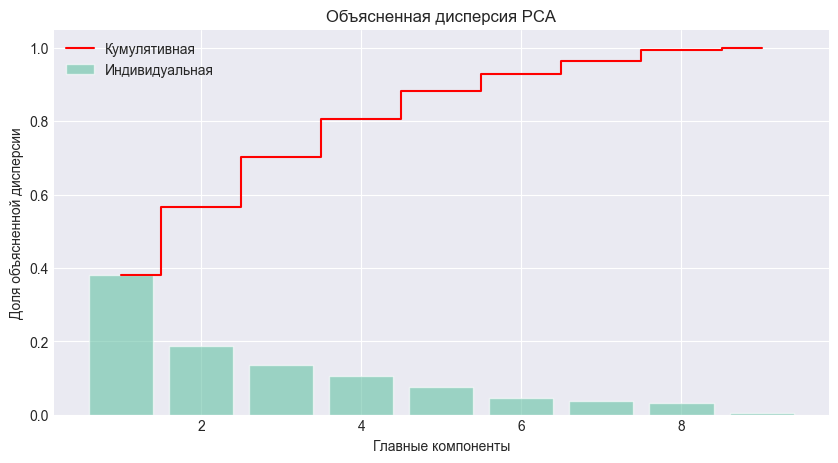

Для сохранения 85% дисперсии нужно 5 компонент
Для сохранения 95% дисперсии нужно 7 компонент
Общая объясненная дисперсия: 1.0000


In [11]:
# Обучаем PCA на всех компонентах
pca_full = PCA()
pca_full.fit(X_train_scaled)

# Доля объясненной дисперсии
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

# График
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_variance_ratio)+1), explained_variance_ratio, alpha=0.6, label='Индивидуальная')
plt.step(range(1, len(cumulative_variance)+1), cumulative_variance, where='mid', label='Кумулятивная', color='red')

plt.xlabel('Главные компоненты')
plt.ylabel('Доля объясненной дисперсии')
plt.title('Объясненная дисперсия PCA')

plt.legend(loc='best')
plt.grid(True)
plt.show()

# Определяем k_pca для 85% и 95%
k_85 = np.argmax(cumulative_variance >= 0.85) + 1
k_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"Для сохранения 85% дисперсии нужно {k_85} компонент")
print(f"Для сохранения 95% дисперсии нужно {k_95} компонент")
print(f"Общая объясненная дисперсия: {cumulative_variance[-1]:.4f}")

#### __2.Трансформация__

In [12]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print(f"Было признаков: {X_train_scaled.shape[1]}")
print(f"Стало признаков после PCA: {pca.n_components_}")
print(f"Форма после PCA: {X_train_pca.shape}")

Было признаков: 9
Стало признаков после PCA: 7
Форма после PCA: (398, 7)


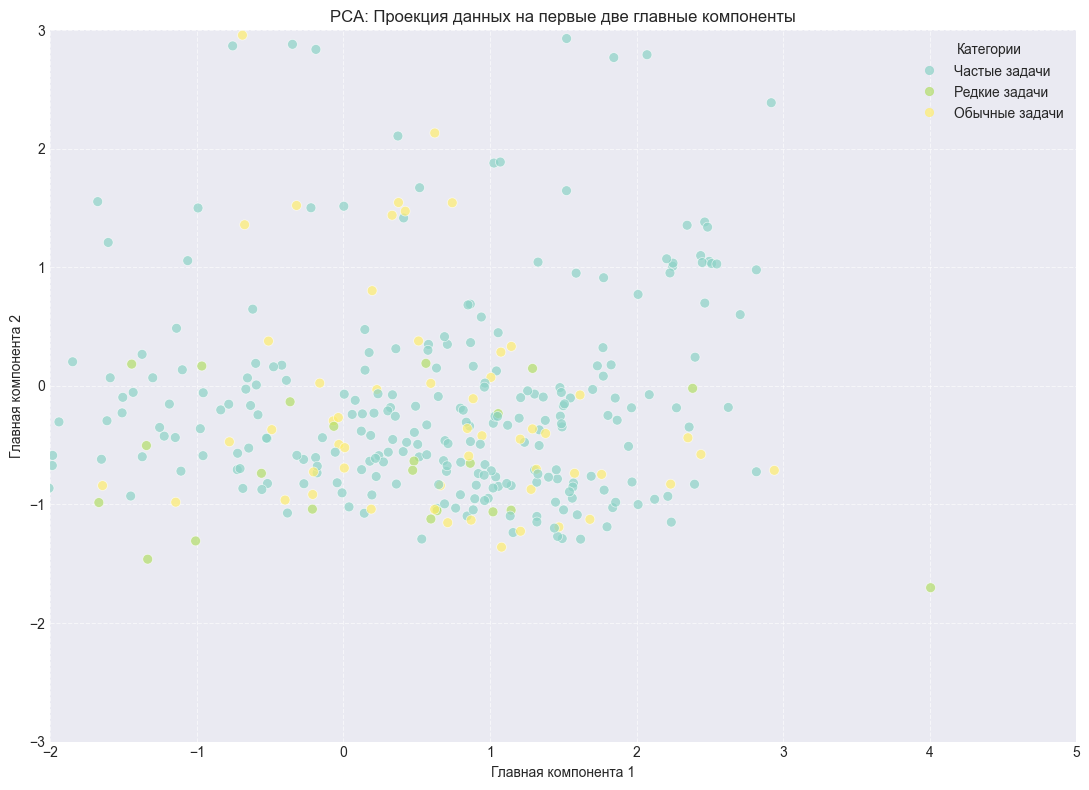

In [20]:
# Получаем уникальные названия категорий и их коды
labels, categories = pd.factorize(y_train)
plt.figure(figsize=(11, 8))

category_names = [
    'Частые задачи',
    'Редкие задачи', 
    'Обычные задачи'
]

scatter = plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1],
                      c=labels,
                      cmap='Set3',
                      alpha=0.7,
                      s=50,
                      edgecolors='white',
                      linewidths=0.5)

# Создаем легенду с названиями классов
plt.legend(handles=scatter.legend_elements()[0],
           labels=category_names,
           title="Категории",
           loc='best',
           bbox_to_anchor=(1, 1))

plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.title('PCA: Проекция данных на первые две главные компоненты')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(-2, 5)  # Покажет область по оси ГК1
plt.ylim(-3, 3)  # Покажет область по оси ГК2

plt.tight_layout()
plt.show()

### __Этап 2: Трансформация пространства методом линейного дискриминантного анализа (LDA)__
#### __1.Обучение и трансформация__

In [21]:
# Максимальное количество компонент LDA = число классов - 1
n_classes = len(np.unique(y_train))
max_lda_components = n_classes - 1
print(f"Максимальное количество компонент LDA: {max_lda_components}")

# Обучаем LDA
lda = LDA(n_components=min(2, max_lda_components))  # для визуализации берем 2
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

print(f"Форма после LDA: {X_train_lda.shape}")

Максимальное количество компонент LDA: 2
Форма после LDA: (398, 2)


#### __2.Визуализация LDA__

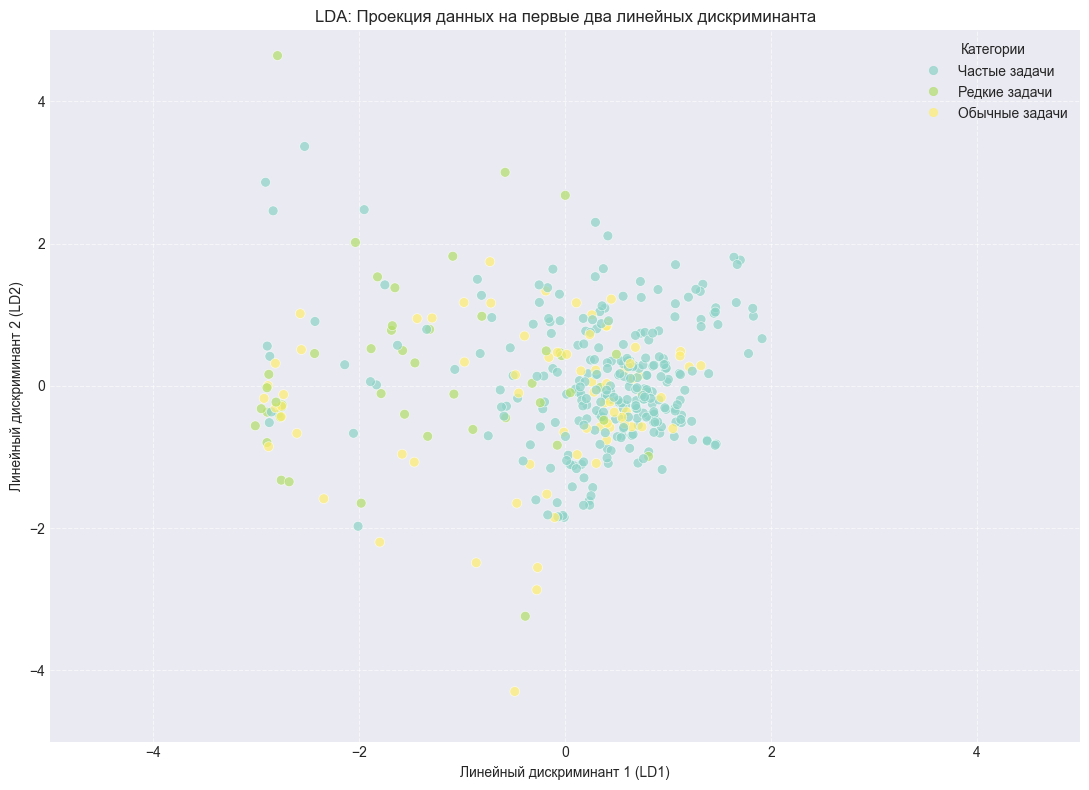

In [23]:
labels, categories = pd.factorize(y_train)
plt.figure(figsize=(11, 8))

category_names = [
    'Частые задачи',
    'Редкие задачи', 
    'Обычные задачи'
]

# Визуализация LDA (используем первые две дискриминантные функции)
scatter = plt.scatter(X_train_lda[:, 0], X_train_lda[:, 1],
                      c=labels,
                      cmap='Set3',
                      alpha=0.7,
                      s=50,
                      edgecolors='white',
                      linewidths=0.5)

# Создаем легенду с названиями классов (категорий)
plt.legend(handles=scatter.legend_elements()[0],
           labels=category_names,
           title="Категории",
           loc='best',
           bbox_to_anchor=(1, 1))

plt.xlabel('Линейный дискриминант 1 (LD1)')
plt.ylabel('Линейный дискриминант 2 (LD2)')
plt.title('LDA: Проекция данных на первые два линейных дискриминанта')
plt.grid(True, linestyle='--', alpha=0.6)

plt.xlim(-5, 5)
plt.ylim(-5, 5)

plt.tight_layout()
plt.show()

### __Этап 3: Сравнение качества классификации в разных пространствах__
#### __1.Обучение и трансформация__